# 03 — Baseline: 5 models × 2 feature sets (RQ1)
Default settings, 5% dataset (seed 42). **With checks** = all 63 features; **raw only** = the 13 data-quality check features removed. Logic: `src/models.py`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent)) 
import config
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from src.features import feature_sets
from src.models import load_features, run_all, timing_test

X, y, issue = load_features(0.05, 42)
X_sets = feature_sets(X)
rate = y.mean()
print('Rows:', len(y), '| anomalies:', int(y.sum()), f'({rate:.2%})')
print({name: Xs.shape[1] for name, Xs in X_sets.items()}, 'features')

Rows: 50417 | anomalies: 2502 (4.96%)
{'with checks': 63, 'raw only': 50} features


Every model uses the same stratified 70/30 split. Unsupervised models train on the training rows **without** labels and flag the `rate` share of rows; their anomaly score is used for PR-AUC. LOF and One-Class SVM use standardised features; supervised models use class weighting.

In [3]:
%pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 1.9 MB/s  0:00:012.3 MB/s eta 0:00:01:01
Note: you may need to restart the kernel to use updated packages.


In [4]:
results, per_issue = run_all(X_sets, y, issue, rate)
results.to_csv(config.RESULTS / 'baseline_results.csv', index=False)
per_issue.to_csv(config.RESULTS / 'baseline_recall_by_issue.csv')
results.round(3)

,features,model,type,precision,recall,F1,PR-AUC,seconds
0,with checks,Isolation Forest,unsupervised,0.231,0.238,0.235,0.158,0.282
1,with checks,LOF,unsupervised,0.113,0.119,0.116,0.084,1.605
2,with checks,One-Class SVM,unsupervised,0.668,0.699,0.683,0.616,7.089
3,with checks,Random Forest,supervised,1.000,1.000,1.000,1.000,1.040
4,with checks,XGBoost,supervised,1.000,0.999,0.999,0.999,0.518
5,raw only,Isolation Forest,unsupervised,0.046,0.048,0.047,0.049,0.319
6,raw only,LOF,unsupervised,0.206,0.214,0.210,0.141,1.294
7,raw only,One-Class SVM,unsupervised,0.103,0.107,0.105,0.072,5.877
8,raw only,Random Forest,supervised,0.439,0.101,0.165,0.230,1.233
9,raw only,XGBoost,supervised,0.542,0.473,0.505,0.469,0.547


**PR-AUC** is the main metric (threshold-free; a random model scores about the anomaly rate, 0.05).

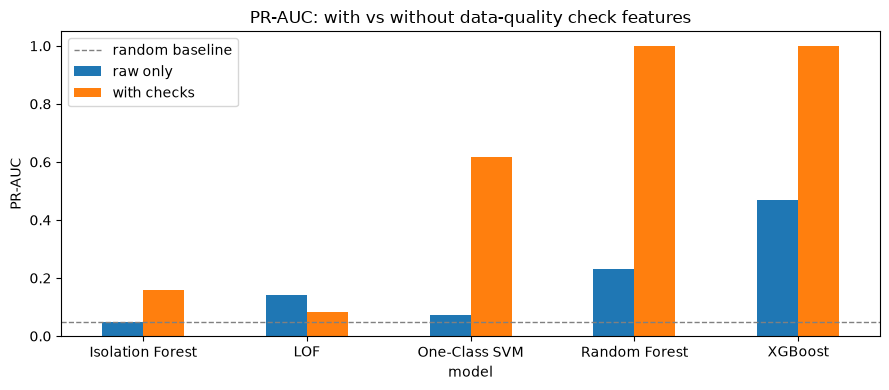

In [5]:
pivot = results.pivot(index='model', columns='features', values='PR-AUC').loc[results['model'].unique()]
ax = pivot.plot.bar(figsize=(9, 4), rot=0)
ax.set_ylabel('PR-AUC'); ax.set_title('PR-AUC: with vs without data-quality check features')
ax.axhline(rate, ls='--', c='grey', lw=1, label='random baseline'); ax.legend()
plt.tight_layout(); plt.savefig(config.RESULTS / 'baseline_pr_auc.png', dpi=150); plt.show()

## Recall per issue type (`none` = false-alarm rate on clean rows)

In [6]:
per_issue.round(2)

issue_type,balance,categorical,crossfield,duplicate,missing,none,numerical
Isolation Forest | with checks,0.19,0.06,0.19,0.41,0.05,0.04,0.52
LOF | with checks,0.04,0.03,0.09,0.09,0.05,0.05,0.43
One-Class SVM | with checks,0.02,1.00,1.00,0.79,1.00,0.02,0.45
Random Forest | with checks,1.00,1.00,1.00,1.00,1.00,0.00,1.00
XGBoost | with checks,0.99,1.00,1.00,1.00,1.00,0.00,1.00
Isolation Forest | raw only,0.05,0.02,0.05,0.05,0.03,0.05,0.09
LOF | raw only,0.04,0.05,0.52,0.03,0.13,0.04,0.53
One-Class SVM | raw only,0.05,0.02,0.06,0.05,0.01,0.05,0.46
Random Forest | raw only,0.00,0.00,0.00,0.00,0.00,0.01,0.62
XGBoost | raw only,0.01,0.85,0.43,0.01,0.67,0.02,0.97


## Timing test: why not use all 1.09M rows?

In [9]:
times, extrapolation = timing_test(X_sets['raw only'])

In [10]:
print(times.round(2), '\n')


       Isolation Forest   LOF  One-Class SVM
5000               0.05  0.03           0.05
10000              0.05  0.13           0.21
20000              0.06  0.21           0.75
35000              0.07  0.61           3.03 



In [11]:
extrapolation.round(2)

,growth_exponent_k,est_minutes_full_data
Isolation Forest,0.22,0.00
LOF,1.43,1.39
One-Class SVM,2.04,55.68


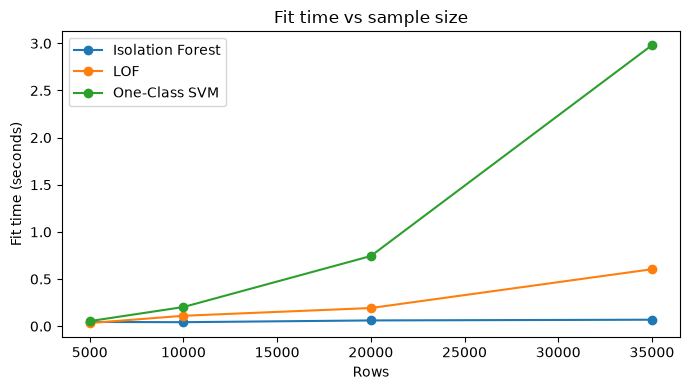

In [8]:
ax = times.plot(marker='o', figsize=(7, 4))
ax.set_xlabel('Rows'); ax.set_ylabel('Fit time (seconds)'); ax.set_title('Fit time vs sample size')
plt.tight_layout(); plt.savefig(config.RESULTS / 'timing_test.png', dpi=150); plt.show()

One-Class SVM grows roughly with the square of the rows (k ≈ 2); LOF grows almost as fast; Isolation Forest stays flat because each tree uses a small subsample. 